# A tiny genome assembler

Lecture 4, Genome Assembly and Annotation. We turn the de Bruijn graph from the blackboard into code, test it on the blackboard reads, and assemble a real plasmid of our isolate from 1,115 Illumina reads. Part 5: we find the genes on that plasmid.

**Finished version** with all outputs.

In [1]:
from collections import Counter
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt

## 1. Cut reads into k-mers

In [2]:
def kmers_of(read, k):
    """All stretches of k letters in a read, one start position after the other."""
    return [read[i:i + k] for i in range(len(read) - k + 1)]


kmers_of("CGATTA", 4)

['CGAT', 'GATT', 'ATTA']

## 2. Build the graph

Nodes are (k−1)-mers. Each k-mer is an edge from its prefix to its suffix.

In [3]:
def build_graph(kmers):
    """De Bruijn graph as a dictionary: node -> list of next nodes."""
    graph = {}
    for kmer in kmers:
        graph.setdefault(kmer[:-1], []).append(kmer[1:])   # an edge from prefix to suffix
    return graph

## 3. Walk the graph

Start where no edge comes in and follow the edges as long as there is exactly one way to go. If every node has an edge coming in, the graph is a circle.

In [4]:
def walk(graph):
    """Follow the edges from a start node; return the sequence and its shape."""
    has_incoming = {node for nexts in graph.values() for node in nexts}
    starts = [node for node in graph if node not in has_incoming]
    path = [starts[0] if starts else min(graph)]   # no start node: a circle, start anywhere
    while len(graph.get(path[-1], [])) == 1:
        nxt = graph[path[-1]][0]
        if nxt == path[0]:   # back at the start: the circle is closed
            return "".join(node[0] for node in path), "circular"
        path.append(nxt)
    return path[0] + "".join(node[-1] for node in path[1:]), "linear"


def assemble(reads, k):
    kmers = sorted({kmer for read in reads for kmer in kmers_of(read, k)})
    return walk(build_graph(kmers))

## 4. Test it on the blackboard

The walkthrough reads, and a second small example (k = 4).

In [5]:
print(assemble(["CGATTA", "ATTACA", "TACAGT"], 4))
print(assemble(["TACCTGA", "ATGCGTA", "CCTGAAT", "GCGTACC"], 4))

('CGATTACAGT', 'linear')
('ATGCGTACCTGAAT', 'linear')


## 5. Real reads: the small plasmid of our isolate

1,115 Illumina reads of 151 letters. (A simplification: all reads are given on the same strand.)

In [6]:
path = Path("psmall_reads.txt")
if not path.exists():   # in Colab
    urlretrieve("https://raw.githubusercontent.com/BioMeDS/lecture-bioinformatics-master/main/lecture_04/psmall_reads.txt", path)
reads = path.read_text().split()
print(len(reads), "reads")
print(reads[0])

1115 reads
TAGAGTACCAGAGCCCTGTGATGCTGTCACGGGGCTTTGTTACATCTGGAGCTTGGTAAACCTCATAAATTCAATTCGCAACGCTCGCCGCAAGGCGTGAACTTGTTTCACGTCGAGGAAGCGGAATTTCTCGAAAGCCTTATACTGTCTC


## 6. Count the k-mers

A k-mer that occurs once or twice most likely contains a sequencing error.

6712 distinct k-mers


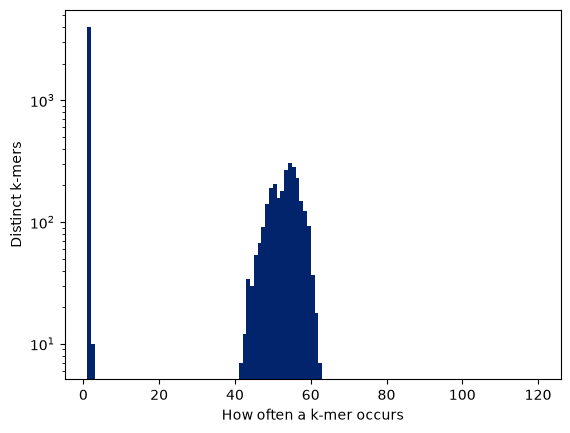

In [7]:
k = 21
counts = Counter(kmer for read in reads for kmer in kmers_of(read, k))
print(len(counts), "distinct k-mers")

plt.hist(list(counts.values()), bins=range(1, 121), color="#02246C")
plt.xlabel("How often a k-mer occurs")
plt.ylabel("Distinct k-mers")
plt.yscale("log")
plt.show()

## 7. Assemble

First with every k-mer, then only with k-mers seen at least 3 times.

In [8]:
graph = build_graph(sorted(counts))
forks = sum(len(nexts) > 1 for nexts in graph.values())
print("all k-mers:", forks, "nodes with more than one way to go")

solid = sorted(kmer for kmer, n in counts.items() if n >= 3)
contig, shape = walk(build_graph(solid))
print("solid k-mers:", len(solid))
print(f"contig: {len(contig):,} letters, {shape}")

all k-mers: 136 nodes with more than one way to go
solid k-mers: 2683
contig: 2,683 letters, circular


Published plasmid pSmall (CP095445.1): 2,683 letters, circular.

# Part 5: Where are the genes?

The small plasmid again, this time from our Unicycler assembly (contig 4). We look for open reading frames (ORFs): a start codon, then codons up to the next stop codon, in one of six frames.

In [9]:
path = Path("psmall_unicycler.fasta")
if not path.exists():   # in Colab
    urlretrieve("https://raw.githubusercontent.com/BioMeDS/lecture-bioinformatics-master/main/lecture_04/psmall_unicycler.fasta", path)
psmall = "".join(line.strip() for line in path.read_text().splitlines()[1:])
print(len(psmall), "letters")

2683 letters


## 8. The genetic code and the other strand

In [10]:
BASES = "TCAG"
AMINO = "FFLLSSSSYY**CC*WLLLLPPPPHHQQRRRRIIIMTTTTNNKKSSRRVVVVAAAADDEEGGGG"
CODE = {a + b + c: AMINO[16 * i + 4 * j + k]
        for i, a in enumerate(BASES) for j, b in enumerate(BASES) for k, c in enumerate(BASES)}
STOPS = {codon for codon, aa in CODE.items() if aa == "*"}


def revcomp(seq):
    """The other strand, read 5' to 3'."""
    return seq.translate(str.maketrans("ACGT", "TGCA"))[::-1]


def translate(seq):
    return "".join(CODE[seq[i:i + 3]] for i in range(0, len(seq) - 2, 3))


translate("ATGGAAAAGCACTTTATC")

'MEKHFI'

## 9. Find the ORFs in six frames

In [11]:
def find_orfs(seq, min_codons=100):
    """ORFs from ATG to the next stop codon, three frames on each strand."""
    orfs = []
    for strand, s in (("+", seq), ("-", revcomp(seq))):
        for frame in range(3):
            start = None
            for i in range(frame, len(s) - 2, 3):
                codon = s[i:i + 3]
                if start is None and codon == "ATG":             # a start codon opens an ORF
                    start = i
                elif start is not None and codon in STOPS:       # the next stop codon in the same frame closes it
                    if (i - start) // 3 >= min_codons:
                        orfs.append((strand, frame, start, i + 3))
                    start = None
    return orfs


orfs = find_orfs(psmall)
for strand, frame, start, end in orfs:
    print(strand, frame + 1, start, end, (end - start) // 3 - 1, "codons")

- 1 624 960 111 codons
- 1 1134 1779 214 codons
- 2 442 844 133 codons


## 10. The longest one, as a protein

What is it? We will ask BLAST in Part 6.

In [12]:
strand, frame, start, end = max(orfs, key=lambda o: o[3] - o[2])
s = psmall if strand == "+" else revcomp(psmall)
print(translate(s[start:end]))

MEKHFINEKFSRDQFTGNRVKNIAFSNCDFSGVDLTDTEFVDCSFYDRNSLEGCDFNRAKLKNASFKSCDLSMSNFKNISALGLEISECLAQGADFRGANFMNMITTRSWFCSAYITKTNLSYANFSRVILEKCELWENRWNGTVITGAVFRGSDLSCGEFSSFDWSLADFTGCDLTGGALGELDARRINLDGVKLDGEQALQLVESLGVIVHR*


Prodigal on the same contig, positions on the given strand: genes at 905-1549 (our 214-codon ORF; on the other strand, as printed above, 1134-1779) and 1840-2241 (133 codons), plus one gene cut in two pieces (1-267 and 2510-2683) where the circle was opened. Our simple ORF finder misses that one, because it reads the circle as a line. It also reports a 111-codon ORF that Prodigal rejects: length alone is not enough.